# **Group 3: Security — Estate CCTV Motion Analytics**

## **Import libraries and load dataset**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


DATA_PATH = "group03_cctv.npz"

data = np.load(DATA_PATH)

## **Inspect dataset structure**

In [2]:
for name in data.files:
    print(name, data[name].shape, data[name].dtype)

frames (360, 72, 96, 3) uint8
minutes_since_1800 (360,) int32
zone_grid (2,) int64


## **Load and convert data**

In [3]:
def load_data(path):
    """Load the .npz file and convert the frames to float.

    Returns
    -------
    frames   : (T, H, W, 3) float64   (uint8 would wrap around when subtracting: 10 - 20 = 246)
    minutes  : (T,)         recorder timestamps, minutes after 18:00 (NOT trusted)
    zone_rows, zone_cols : ints, number of zone rows / columns
    """
    data = np.load(path)
    frames = data["frames"].astype(np.float64)
    assert frames.ndim == 4 and frames.shape[3] == 3, "frames must be (T, H, W, 3)"
    minutes = data["minutes_since_1800"]
    assert minutes.shape == (frames.shape[0],)
    zone_rows, zone_cols = (int(v) for v in data["zone_grid"])
    return frames, minutes, zone_rows, zone_cols


frames, minutes, zone_rows, zone_cols = load_data(DATA_PATH)
n_frames, height, width, channels = frames.shape
print("frames:", frames.shape, frames.dtype)
print("zone grid:", zone_rows, "x", zone_cols)

frames: (360, 72, 96, 3) float64
zone grid: 4 x 4


## **Divide differences into security zones**

In [4]:
def frame_differences(frames):
    """Absolute difference between consecutive frames, averaged over colour.

    (T, H, W, 3) -> (T-1, H, W)
    """
    diff = np.mean(np.abs(np.diff(frames, axis=0)), axis=3)
    assert diff.shape == (frames.shape[0] - 1, frames.shape[1], frames.shape[2])
    return diff


def zone_changes(frame_diff, zone_rows, zone_cols):
    """Average the frame differences inside each zone.

    (T-1, H, W) -> reshape (T-1, zr, H/zr, zc, W/zc)
                -> transpose (T-1, zr, zc, H/zr, W/zc)
                -> mean over the last two axes -> (T-1, zr, zc)
    """
    n_pairs, h, w = frame_diff.shape
    zh, zw = h // zone_rows, w // zone_cols
    assert h == zone_rows * zh and w == zone_cols * zw, "zones must divide the frame exactly"

    blocks = frame_diff.reshape(n_pairs, zone_rows, zh, zone_cols, zw)
    assert blocks.shape == (n_pairs, zone_rows, zh, zone_cols, zw)

    blocks = blocks.transpose(0, 1, 3, 2, 4)
    assert blocks.shape == (n_pairs, zone_rows, zone_cols, zh, zw)

    zc = blocks.mean(axis=(3, 4))
    assert zc.shape == (n_pairs, zone_rows, zone_cols)
    return zc


frame_diff = frame_differences(frames)
zone_change = zone_changes(frame_diff, zone_rows, zone_cols)
print("Frame difference shape:", frame_diff.shape)
print("Zone change shape:", zone_change.shape)

Frame difference shape: (359, 72, 96)
Zone change shape: (359, 4, 4)


## **Detect lighting anomalies**

In [5]:
def brightness_series(frames):
    """(T, H, W, 3) -> (T,)  average brightness of every frame."""
    b = frames.mean(axis=(1, 2, 3))
    assert b.shape == (frames.shape[0],)
    return b


def detect_flashes(brightness, k=6, floor=1.0):
    """Find single frames that are much brighter than the frames around them.

    A flash frame is far above the average of its two neighbours.
    (T,) -> flash frame indexes (n_flash,)
    The threshold uses the median and MAD, so a few extreme values do not distort it.
    """
    neighbour_avg = (brightness[:-2] + brightness[2:]) / 2
    residual = brightness[1:-1] - neighbour_avg            # (T-2,)
    med = np.median(residual)
    mad = np.median(np.abs(residual - med))
    threshold = med + k * max(1.4826 * mad, floor)
    flash_frames = np.where(residual > threshold)[0] + 1   # +1: residual[0] is frame 1
    return flash_frames, residual, threshold


def flash_pair_mask(flash_frames, n_pairs):
    """A flash in frame i corrupts the differences (i-1 -> i) and (i -> i+1).

    -> bool (T-1,)  True = this frame difference must be ignored.
    """
    invalid = np.zeros(n_pairs, dtype=bool)
    invalid[flash_frames - 1] = True
    invalid[flash_frames] = True
    return invalid


frame_brightness = brightness_series(frames)
light_frames, light_residual, light_threshold = detect_flashes(frame_brightness)
invalid_pairs = flash_pair_mask(light_frames, n_frames - 1)

print("Flash frames:", light_frames.tolist())
print("Brightness jump vs neighbours:", np.round(light_residual[light_frames - 1], 1).tolist())
print("Threshold used:", round(float(light_threshold), 2))
print("Frame differences ignored:", int(invalid_pairs.sum()))

Flash frames: [10, 93, 195]
Brightness jump vs neighbours: [53.4, 37.1, 22.2]
Threshold used: 6.0
Frame differences ignored: 6


## **Detect active zones**

In [6]:
def active_zones(zone_change, invalid_pairs, k=3, floor=1.0):
    """A zone is active when its change is well above that zone's normal level.

    (T-1, zr, zc) -> bool (T-1, zr, zc); ignored frame differences are set to False.
    """
    med = np.median(zone_change, axis=0)                                 # (zr, zc)
    mad = np.median(np.abs(zone_change - med), axis=0)                   # (zr, zc)
    threshold = med + k * np.maximum(1.4826 * mad, floor)
    active = zone_change > threshold
    active[invalid_pairs] = False
    assert active.shape == zone_change.shape
    return active


zone_active = active_zones(zone_change, invalid_pairs)
print("Active zone-differences:", int(zone_active.sum()))

Active zone-differences: 59


## **Reconstruct accurate timestamps**

In [7]:
def find_clock_jumps(minutes):
    """Evidence for the clock problem: where do the recorder timestamps jump?

    (T,) -> frame indexes where the gap is not the usual one, and the size of the gap.
    """
    gaps = np.diff(minutes)
    usual = np.median(gaps)
    idx = np.where(gaps != usual)[0]
    return idx + 1, gaps[idx], usual


def clock_label(total_minutes):
    """Minutes since midnight -> 'HH:MM'."""
    t = int(total_minutes)
    return f"{(t // 60) % 24:02d}:{t % 60:02d}"


def frame_time(frame_index):
    """True time of a frame: 18:00 + 2 minutes x frame number."""
    return clock_label(18 * 60 + 2 * frame_index)


jump_frames, jump_sizes, usual_gap = find_clock_jumps(minutes)
print("Usual gap between recorder timestamps:", usual_gap, "minutes")
for f, g in zip(jump_frames, jump_sizes):
    print(f"Clock jumps at frame {f}: gap of {g} min instead of {usual_gap:.0f} "
          f"(true time {frame_time(f)}, recorder says {clock_label(18*60 + minutes[f])})")

Usual gap between recorder timestamps: 2.0 minutes
Clock jumps at frame 175: gap of 22 min instead of 2 (true time 23:50, recorder says 00:10)


## **Detect camera movement**

In [8]:
def find_events(zone_active):
    """Group runs of consecutive active frame differences into events.

    (T-1, zr, zc) bool -> list of dicts with first/last frame difference and the zones touched.
    Frame difference j compares frame j with frame j+1, so the change first appears in frame j+1.
    """
    active_pairs = np.where(zone_active.any(axis=(1, 2)))[0]
    if active_pairs.size == 0:
        return []
    runs = np.split(active_pairs, np.where(np.diff(active_pairs) != 1)[0] + 1)
    events = []
    for run in runs:                                  # small loop over the events only
        first, last = int(run[0]), int(run[-1])
        zones = np.argwhere(zone_active[first:last + 1].any(axis=0)) + 1   # 1-indexed (row, col)
        events.append({
            "first_pair": first, "last_pair": last,
            "start_frame": first + 1, "end_frame": last + 1,
            "zones": [(int(r), int(c)) for r, c in zones],
        })
    return events


def split_camera_shifts(events, frames, frame_diff, ratio=1.5):
    """Separate real movement from a knocked camera.

    A person walks through and leaves: the picture AFTER the event looks like the picture BEFORE it.
    A knocked camera stays shifted: the picture after the event is still different.
    Score = mean |frame before - frame after|. It is compared with the normal
    frame-to-frame change, so the rule adapts to each file.
    """
    baseline = np.median(frame_diff.mean(axis=(1, 2)))
    real, camera = [], []
    for ev in events:
        before = frames[ev["first_pair"]]
        after = frames[min(ev["last_pair"] + 2, frames.shape[0] - 1)]
        score = float(np.abs(before - after).mean())
        ev = {**ev, "persistence": round(score, 2)}
        (camera if score > ratio * baseline else real).append(ev)
    return real, camera, baseline


candidate_events = find_events(zone_active)
events, camera_events, baseline_change = split_camera_shifts(candidate_events, frames, frame_diff)

print("Normal frame-to-frame change:", round(float(baseline_change), 2))
print("Candidate events:", len(candidate_events))
for ev in sorted(events + camera_events, key=lambda e: e["first_pair"]):
    kind = "CAMERA SHIFT (removed)" if ev in camera_events else "movement"
    print(f"  frames {ev['start_frame']}-{ev['end_frame']}  persistence score {ev['persistence']:.2f}  -> {kind}")

Normal frame-to-frame change: 2.83
Candidate events: 8
  frames 26-29  persistence score 2.94  -> movement
  frames 75-80  persistence score 3.75  -> movement
  frames 145-148  persistence score 3.00  -> movement
  frames 152-155  persistence score 2.95  -> movement
  frames 185-189  persistence score 2.82  -> movement
  frames 243-243  persistence score 5.26  -> CAMERA SHIFT (removed)
  frames 283-286  persistence score 3.28  -> movement
  frames 290-293  persistence score 3.27  -> movement


## **Detect consecutive motion events**

In [9]:
def add_times(events):
    """Attach the true clock time and an after-midnight flag to each event."""
    out = []
    for ev in events:
        start_min, end_min = 2 * ev["start_frame"], 2 * ev["end_frame"]   # minutes after 18:00
        out.append({**ev,
                    "start_time": frame_time(ev["start_frame"]),
                    "end_time": frame_time(ev["end_frame"]),
                    "after_midnight": start_min >= 6 * 60})              # 6 h after 18:00 = 00:00
    return out


events = add_times(events)
after_midnight = [ev for ev in events if ev["after_midnight"]]
print("Real events:", len(events), "| after midnight:", len(after_midnight))

Real events: 7 | after midnight: 3


## **Effect of each fix on the results**

In [10]:
no_fix = find_events(active_zones(zone_change, np.zeros(n_frames - 1, dtype=bool)))
flash_fixed = find_events(zone_active)

print("Events with no fixes at all:            ", len(no_fix))
print("Events after masking flash frames:      ", len(flash_fixed), f"({len(no_fix) - len(flash_fixed)} false alerts removed)")
print("Events after also removing camera shift:", len(events), f"({len(flash_fixed) - len(events)} false alert removed)")

print()
print("If the recorder clock had been trusted, these events would be mislabelled:")
for ev in events:
    if len(jump_frames) > 0 and ev["start_frame"] >= jump_frames[0]:
        wrong = clock_label(18 * 60 + minutes[ev["start_frame"]])
        print(f"  true {ev['start_time']}  would read {wrong}")

Events with no fixes at all:             11
Events after masking flash frames:       8 (3 false alerts removed)
Events after also removing camera shift: 7 (1 false alert removed)

If the recorder clock had been trusted, these events would be mislabelled:
  true 00:10  would read 00:30
  true 03:26  would read 03:46
  true 03:40  would read 04:00


## **One function runs everything**

In [11]:
def run_pipeline(path, verbose=True):
    """Run the whole CCTV pipeline on any data file of this type.

    path -> dict with: events, camera_events, flash_frames, clock_jumps,
            zone_active (T-1, zr, zc), brightness (T,), counts
    """
    frames, minutes, zr, zc = load_data(path)                                   # (T,H,W,3), (T,)
    fdiff = frame_differences(frames)                                           # (T-1,H,W)
    zchange = zone_changes(fdiff, zr, zc)                                       # (T-1,zr,zc)

    brightness = brightness_series(frames)                                      # (T,)
    flashes, _, _ = detect_flashes(brightness)
    invalid = flash_pair_mask(flashes, frames.shape[0] - 1)                     # (T-1,)
    zactive = active_zones(zchange, invalid)                                    # (T-1,zr,zc)

    jump_f, jump_g, usual = find_clock_jumps(minutes)

    candidates = find_events(zactive)
    real, camera, baseline = split_camera_shifts(candidates, frames, fdiff)
    for ev in camera:                      # a camera shift must not appear in the zone map either
        zactive[ev["first_pair"]:ev["last_pair"] + 1] = False
    real = add_times(real)
    camera = add_times(camera)

    no_fix = find_events(active_zones(zchange, np.zeros(frames.shape[0] - 1, dtype=bool)))
    result = {
        "events": real, "camera_events": camera,
        "flash_frames": flashes, "clock_jumps": list(zip(jump_f.tolist(), jump_g.tolist())),
        "zone_active": zactive, "brightness": brightness,
        "counts": {"no_fix": len(no_fix), "after_flash_fix": len(candidates), "final": len(real)},
    }
    if verbose:
        print_report(result)
    return result


def print_report(result):
    """Print the alert log and the after-midnight summary."""
    print("SECURITY ALERT LOG")
    for n, ev in enumerate(result["events"], 1):
        print(f"Event {n}: {ev['start_time']} - {ev['end_time']} | Zones (row, col): {ev['zones']}")
    after = [ev for ev in result["events"] if ev["after_midnight"]]
    print("\nFlash frames removed:", result["flash_frames"].tolist())
    print("Camera shifts removed:", [ev["start_time"] for ev in result["camera_events"]])
    print("Clock jumps (frame, gap in min):", result["clock_jumps"])
    print("\nEvents occurring after midnight:", len(after))
    for ev in after:
        print(" ", ev["start_time"], ev["zones"])

## **Generate security alert log**

In [12]:
results = run_pipeline(DATA_PATH)

SECURITY ALERT LOG
Event 1: 18:52 - 18:58 | Zones (row, col): [(3, 1), (4, 1)]
Event 2: 20:30 - 20:40 | Zones (row, col): [(3, 2), (3, 3)]
Event 3: 22:50 - 22:56 | Zones (row, col): [(3, 3), (3, 4)]
Event 4: 23:04 - 23:10 | Zones (row, col): [(3, 2)]
Event 5: 00:10 - 00:18 | Zones (row, col): [(3, 3), (3, 4), (4, 3), (4, 4)]
Event 6: 03:26 - 03:32 | Zones (row, col): [(3, 3), (4, 3)]
Event 7: 03:40 - 03:46 | Zones (row, col): [(4, 2), (4, 3)]

Flash frames removed: [10, 93, 195]
Camera shifts removed: ['02:06']
Clock jumps (frame, gap in min): [(175, 22)]

Events occurring after midnight: 3
  00:10 [(3, 3), (3, 4), (4, 3), (4, 4)]
  03:26 [(3, 3), (4, 3)]
  03:40 [(4, 2), (4, 3)]


## **Visualise results**

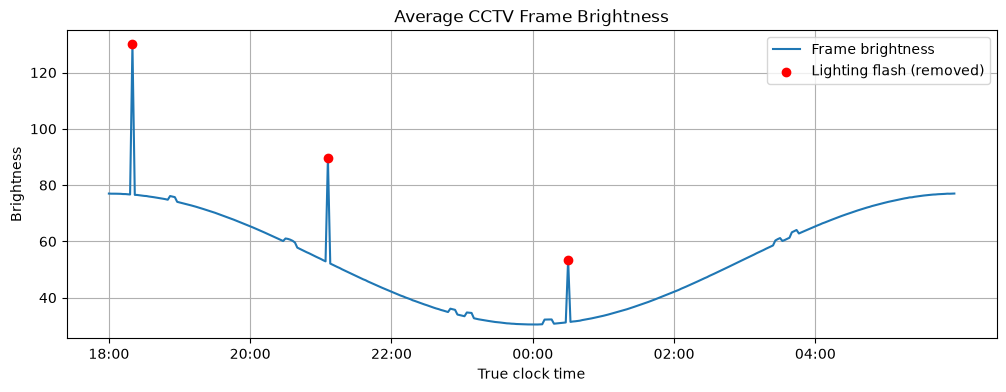

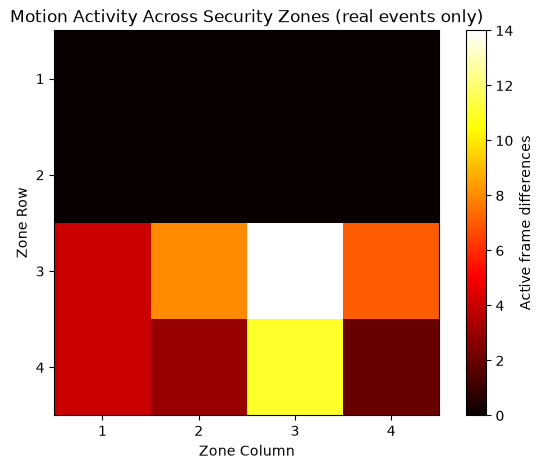

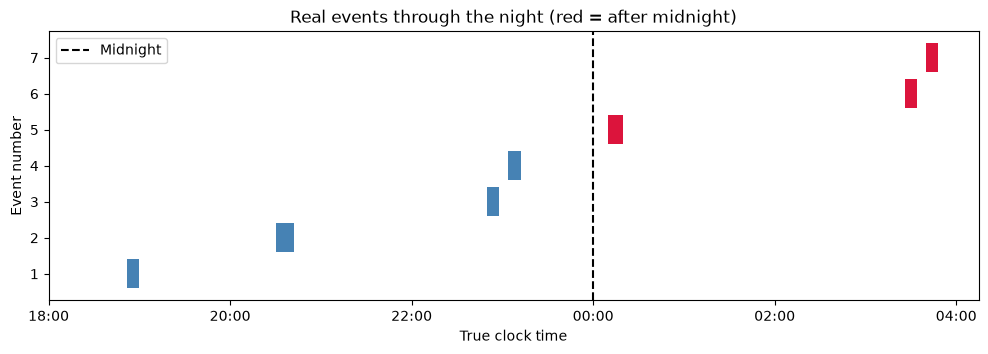

In [13]:
def clock_ticks(n_frames, every=60):
    """Tick positions and 'HH:MM' labels, one every `every` frames (60 frames = 2 hours)."""
    pos = np.arange(0, n_frames, every)
    return pos, [frame_time(p) for p in pos]


# Chart 1: brightness over the night, with the flash frames marked
b = results["brightness"]
pos, labels = clock_ticks(len(b))
plt.figure(figsize=(12, 4))
plt.plot(b, label="Frame brightness")
plt.scatter(results["flash_frames"], b[results["flash_frames"]], color="red", zorder=3, label="Lighting flash (removed)")
plt.xticks(pos, labels)
plt.title("Average CCTV Frame Brightness")
plt.xlabel("True clock time")
plt.ylabel("Brightness")
plt.legend()
plt.grid()
plt.show()

# Chart 2: where the real movement happened
zone_counts = results["zone_active"].sum(axis=0)
plt.figure(figsize=(7, 5))
plt.imshow(zone_counts, cmap="hot")
plt.colorbar(label="Active frame differences")
plt.title("Motion Activity Across Security Zones (real events only)")
plt.xlabel("Zone Column")
plt.ylabel("Zone Row")
plt.xticks(range(zone_cols), range(1, zone_cols + 1))
plt.yticks(range(zone_rows), range(1, zone_rows + 1))
plt.show()

# Chart 3: when the events happened
fig, ax = plt.subplots(figsize=(12, 3.5))
for n, ev in enumerate(results["events"], 1):
    colour = "crimson" if ev["after_midnight"] else "steelblue"
    ax.barh(n, ev["end_frame"] - ev["start_frame"] + 1, left=ev["start_frame"], color=colour)
ax.axvline(180, color="black", linestyle="--", label="Midnight")
ax.set_xticks(*clock_ticks(n_frames))
ax.set_yticks(range(1, len(results["events"]) + 1))
ax.set_xlabel("True clock time")
ax.set_ylabel("Event number")
ax.set_title("Real events through the night (red = after midnight)")
ax.legend()
plt.show()

## **Business answers**

**1. Alert log** – see the log above: every real event with its true clock time and zones (row, column).

**2. After midnight** – state the number of events after midnight (from the output above), the zones where they happened, and the times.

**Recommendation** – write this in your own words, using the numbers above. Think about:
- Which zones are repeatedly active after midnight, and what that suggests about where to put a patrol or camera focus.
- Which times cluster (are any events close together?), and what that means for patrol timing.
- Whether lighting should be improved in the zones where night events happen.

## **Optional benchmark: Python loops vs NumPy**

In [14]:
import timeit

sample = frames[:20]          # 20 frames only, so the slow loop version finishes quickly


def diff_with_loops(fr):
    """Same result as frame_differences, written with Python loops (slow)."""
    t, h, w, c = fr.shape
    out = np.zeros((t - 1, h, w))
    for i in range(t - 1):
        for y in range(h):
            for x in range(w):
                s = 0.0
                for ch in range(c):
                    s += abs(fr[i + 1, y, x, ch] - fr[i, y, x, ch])
                out[i, y, x] = s / c
    return out


assert np.allclose(diff_with_loops(sample), frame_differences(sample))   # same answer

t_loop = timeit.timeit(lambda: diff_with_loops(sample), number=3) / 3
t_numpy = timeit.timeit(lambda: frame_differences(sample), number=3) / 3
print(f"Python loops: {t_loop:.3f} s | NumPy: {t_numpy:.5f} s | NumPy is about {t_loop / t_numpy:.0f}x faster")

Python loops: 0.284 s | NumPy: 0.00441 s | NumPy is about 64x faster
